# 06 - Explainability (bonus)

| Part | Method |
|---|---|
| Global | top TF-IDF features per class by logistic regression coefficient |
| Local | per-text feature contributions (`tfidf value x coefficient`) for correct and wrong predictions |

- Model: reference TF-IDF + LogReg from 04 (same subsample, same config)
- For a linear model the contribution of each n-gram to a class score is exact, no approximation as in LIME / SHAP
- Kaggle: CPU is enough, Internet on, competition data attached

## Setup

In [1]:
import subprocess
import sys

REPO = "https://github.com/mohinska/ai_hw3_AIGenTextDetection.git"
REPO_DIR = "/tmp/repo"

subprocess.run(["rm", "-rf", REPO_DIR], check=True)
subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")

In [2]:
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED
from features import fit_tfidf, tfidf_feature_names, tfidf_transform

warnings.filterwarnings("ignore", category=UserWarning)

## Config

In [3]:
N_TRAIN = 60_000
REF_FEATURES = ["char_wb_2-5"]             # best feature set from 02
REF_C = 2.0                                 # best C from 02
TOP_K = 15

## Fit the reference model

In [4]:
train_df, _, _ = common.load_data()
trn, val = common.split_train_val(train_df)
trn = common.subsample(trn, N_TRAIN)
y_val = val[LABEL_COL].to_numpy()

vecs = fit_tfidf(REF_FEATURES, trn[TEXT_COL].fillna(""))
X_trn = tfidf_transform(vecs, trn[TEXT_COL].fillna(""))
X_val = tfidf_transform(vecs, val[TEXT_COL].fillna(""))
clf = LogisticRegression(C=REF_C, max_iter=2000, random_state=SEED).fit(X_trn, trn[LABEL_COL])
val_pred = clf.predict(X_val)
feat = tfidf_feature_names(vecs)
CLS = {c: i for i, c in enumerate(clf.classes_)}
print(f"val macro-F1: {f1_score(y_val, val_pred, average='macro'):.4f} | features: {len(feat):,}")

val macro-F1: 0.8724 | features: 300,000


## Global: features with the largest coefficients per class

- `word_1-2:` = word / word-pair, `char_wb_2-5:` = character n-gram (`_` marks a space)

In [5]:
def top_features(cls, k=TOP_K, prefix=None):
    coef = clf.coef_[CLS[cls]]
    mask = np.char.startswith(feat.astype(str), prefix) if prefix else np.ones(len(feat), bool)
    idx = np.where(mask)[0][np.argsort(-coef[mask])[:k]]
    return [(feat[i].split(":", 1)[1].replace(" ", "_"), round(float(coef[i]), 2)) for i in idx]


for prefix in [n + ":" for n in REF_FEATURES]:
    print(prefix)
    display(pd.DataFrame({c: [f"{f} ({w})" for f, w in top_features(c, prefix=prefix)] for c in LABELS}))

char_wb_2-5:


,human,ai,fusion
0,.'_ (6.52),!_ (5.29),_'_ (8.79)
1,.' (5.91),?_ (4.26),"_""_ (6.49)"
2,.’_ (4.64),"_"" (3.88)",_. (6.18)
3,.’ (4.21),’s_ (3.64),_.. (5.2)
4,_Dank (3.89),’s (3.61),_... (5.09)
5,Dank (3.88),"""_ (2.77)",_' (4.89)
6,Dank. (3.81),_“ (2.6),_’_ (4.65)
7,ank._ (3.69),”_ (2.44),_… (4.6)
8,ank. (3.69),t’s_ (2.38),_’ (4.51)
9,_Dan (3.23),t’s (2.37),_U._ (4.08)


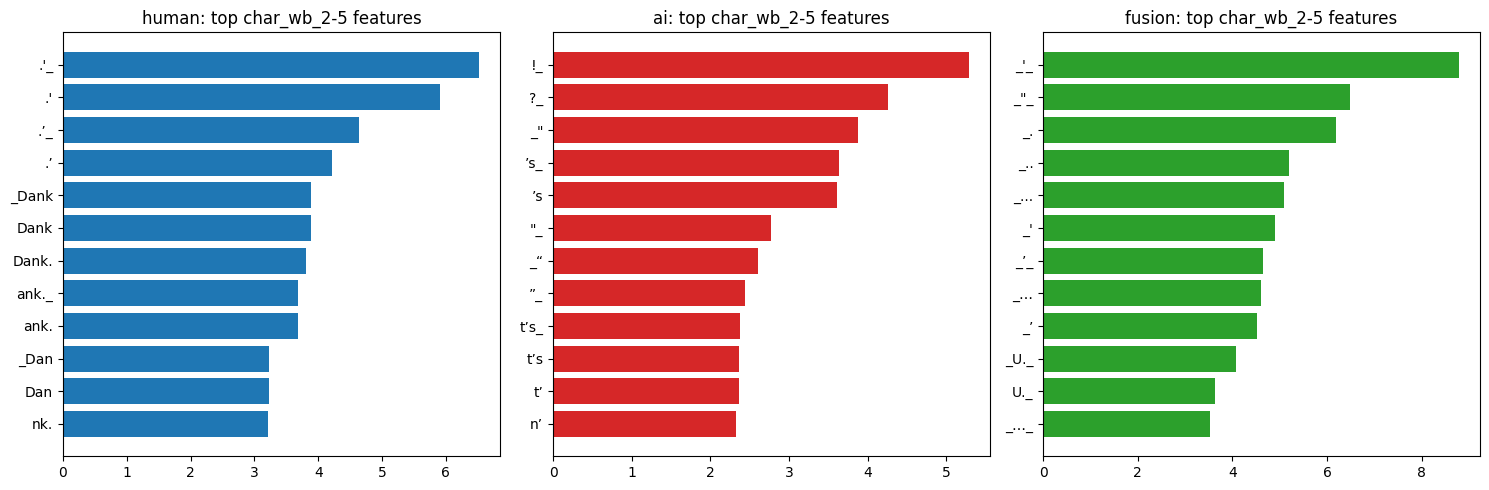

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axes, LABELS):
    names_, weights = zip(*top_features(c, k=12, prefix=REF_FEATURES[0] + ":"))
    ax.barh(names_[::-1], weights[::-1], color={"human": "tab:blue", "ai": "tab:red", "fusion": "tab:green"}[c])
    ax.set_title(f"{c}: top {REF_FEATURES[0]} features")
common.save_fig("xai_top_features.png")

## Local: why a given text got its label

- Contribution of feature j to class k = `tfidf_j(text) x coef_kj`
- Shown: one correct prediction per class and the most common error (true `fusion`, predicted `human`)

In [7]:
def explain(i, k=10):
    row = X_val[i]
    pred = val_pred[i]
    contrib = row.multiply(clf.coef_[CLS[pred]]).tocsr()
    order = np.argsort(-contrib.data)[:k]
    text = textwrap.shorten(val[TEXT_COL].iloc[i], 300)
    print(f"--- true: {y_val[i]} | pred: {pred} | domain: {val['domain'].iloc[i]}\n{text}")
    display(pd.DataFrame({"feature": [feat[contrib.indices[j]].split(":", 1)[1].replace(" ", "_") for j in order],
                          "contribution": np.round(contrib.data[order], 3)}).T)


rng = np.random.default_rng(SEED)
cases = [(c, c) for c in LABELS] + [("fusion", "human")]
for true, pred in cases:
    idx = np.where((y_val == true) & (val_pred == pred))[0]
    if len(idx):
        explain(rng.choice(idx))

--- true: human | pred: human | domain: student_essays
The author supports his idea by pointing out the risks and challenges the scientists,researchers and astronomos could have by going to Venus and trying to get just a little sample of rock,or something else they see it cold be intersting to study and investigate more about it like what it [...]


,0,1,2,3,4,5,6,7,8,9
feature,_be_,enus_,enus,nus_,arth_,arth,_is_,_use,have_,be_
contribution,0.066,0.058,0.05,0.049,0.048,0.046,0.044,0.041,0.039,0.037


--- true: ai | pred: ai | domain: cnn_news
In the electric atmosphere of the quarterfinals, the world held its breath as Brazil faced off against Chile in a clash that promised fireworks and fervor. The stage was set at the iconic Maracanã Stadium, a hallowed ground that has witnessed countless moments of footballing history. As the [...]


,0,1,2,3,4,5,6,7,8,9
feature,’s_,’s,_“,”_,ling_,lin,ling,",”_",_urg,",”"
contribution,0.057,0.056,0.029,0.028,0.017,0.016,0.016,0.016,0.016,0.016


--- true: fusion | pred: fusion | domain: bundestag
Herr Präsident! Liebe Kolleginnen und Kollegen! Es war ja schon viel von Familie, Kindern und auch dem Schutzbedürfnis von Kindern die Rede. Ich möchte folgendermaßen beginnen: Für uns ist es so, dass Kinder überall gleich viel wert sind, egal ob in Deutschland oder anderswo auf der Welt. Für [...]


,0,1,2,3,4,5,6,7,8,9
feature,._,_Es_,Es_,ndern,au_,_Das_,Das_,Präsi,_Frau,äside
contribution,0.035,0.027,0.026,0.026,0.025,0.024,0.023,0.023,0.022,0.022


--- true: fusion | pred: human | domain: cnn_news
The Duchess of Cambridge will be guest of honour at a spectacular celebration in Malta next month, on her first solo foreign tour on behalf of the Queen. Kate will leave her young son, Prince George, behind – as well as her husband, Prince William - for two days of official events to mark the [...]


,0,1,2,3,4,5,6,7,8,9
feature,_._,will_,will,_will,_be_,_wil,wil,Vi,ill_,_Vi
contribution,0.037,0.033,0.033,0.033,0.028,0.028,0.027,0.023,0.022,0.022


## Conclusions

- **Punctuation and typography drive the model**, not vocabulary: the strongest n-grams of every class are quotes, apostrophes and spacing
- **`ai`:** typographic apostrophes and quotes (`’s`, `“`, `”`), `!`, `?` -> the generator writes curly quotes, humans mostly do not
- **`human`:** straight apostrophe after a period (`.'`) and German `Dank.` (end of a Bundestag speech)
- **`fusion`:** a space before punctuation (`_'_`, `_._`, `_...`, `_…`) -> likely seams where rewritten parts were spliced into the human text
- **Local example (`ai`, `cnn_news`):** decided by `’s` and `“` / `”` alone, not by the content
- **Typical error (`fusion` -> `human`):** the decision rests on common words (`will`, `be`) -> the rewritten part leaves no visible formatting trace
- **Takeaway:** the TF-IDF model detects formatting artifacts of the generation pipeline; this works on the test set (LB close to val) but would not transfer to cleanly formatted texts